# Loan Default Risk Analysis and Prediction Using Supervised Machine Learning

## Introduction and Problem Statement

Lenders record whether past loans were repaid or ended in default. This project studies patterns in a historical loan dataset and evaluates five supervised classifiers that predict the recorded loan default status (`loan_status`) from borrower and loan characteristics.

The project is an educational prediction exercise. It does not claim that any variable causes default, and it is not a complete credit-decision system.

## Story Behind the Dataset

Loan default prediction is an important application of data analysis in the financial sector. Applicant information, loan characteristics, and credit history can provide useful insights into patterns associated with repayment and default.

This project uses a loan credit risk dataset containing applicant and loan-related information, with `loan_status` as the target variable. The dataset is explored and prepared before five supervised classification models are trained and evaluated.

The project aims to understand how these classifiers perform on the available data. The results depend on the dataset and evaluation method and should not be interpreted as proof that any particular factor causes loan default.

## Project Objectives

1. To preprocess the loan dataset and perform exploratory data analysis.

2. To evaluate Logistic Regression for loan default prediction.

3. To evaluate K-Nearest Neighbors (KNN) for loan default prediction.

4. To evaluate Gaussian Naive Bayes for loan default prediction.

5. To evaluate Decision Tree for loan default prediction.

6. To evaluate Random Forest for loan default prediction.

7. To compare the five classifiers using Accuracy, Precision, Recall,
   Confusion Matrix and Classification Report.

8. To identify the best-performing classifier and summarize the
   key findings and limitations.

## Dataset Source

Credit Risk Dataset, Kaggle: https://www.kaggle.com/datasets/laotse/credit-risk-dataset

File used: `credit_risk_dataset.csv`

## 1. Understanding the Dataset

In this section, we explore the loan credit risk dataset to understand its structure and contents. We examine the number of records, column names, data types, and summary statistics. This initial inspection helps identify the variables available for analysis and prepares us for the data preprocessing stage.

### 1.1 Importing Basic Libraries

Pandas handles tabular data and NumPy supports numerical operations. These two are needed to load and inspect the data.

In [53]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

### 1.2 Loading the Dataset

In [54]:
df = pd.read_csv("credit_risk_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully!
Number of rows and columns: (32581, 12)


### 1.3 First and Last Five Records

In [55]:
print("First five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

First five records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Last five records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


### 1.4 Column Names and Data Types

In [56]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   

**Observation:** The dataset has 32,581 rows and 12 columns: 8 numerical (including the target `loan_status`) and 4 categorical. `person_emp_length` and `loan_int_rate` have fewer non-null values than the other columns, so they contain missing values.

### 1.5 Summary Statistics

Summary statistics reveal the typical range of each variable and expose unusual values.

In [57]:
# Numerical columns
print("Numerical Summary:")
display(df.describe())

# Categorical columns
print("Categorical Summary:")
categorical_columns = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())

Numerical Summary:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Categorical Summary:

 person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

 loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

 loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

 cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


### 1.6 The Target Variable

`loan_status` is the target. In this dataset, `0` means the loan was **not** recorded as a default and `1` means it **was** recorded as a default.

In [58]:
print(df['loan_status'].value_counts())
print("\nPercentage of each class:")
print((df['loan_status'].value_counts(normalize=True) * 100).round(2))

loan_status
0    25473
1     7108
Name: count, dtype: int64

Percentage of each class:
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


**Observation:** About 78% of loans are non-default (0) and about 22% are default (1). The classes are **imbalanced**, so accuracy alone will not tell the full story.

# 2. Data Preprocessing and Cleaning

We check for missing values, duplicates, inconsistent labels and invalid numbers. All cleaning is done on a copy, so the original `df` stays unchanged.

### 2.1 Creating a Working Copy

In [59]:
df_clean = df.copy()
print("Working dataset shape:", df_clean.shape)

Working dataset shape: (32581, 12)


### 2.2 Checking Missing Values

In [60]:
missing = df_clean.isnull().sum()
missing_percent = (missing / len(df_clean) * 100).round(2)

display(pd.DataFrame({'Missing values': missing, 'Percentage': missing_percent}))

,Missing values,Percentage
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


**Observation:** Only `person_emp_length` (895 missing, 2.75%) and `loan_int_rate` (3,116 missing, 9.56%) have missing values.

### 2.3 Checking and Removing Duplicate Records

Exact duplicate rows add no new information and can appear in both the training and test sets, so they are removed.

In [61]:
print("Duplicate records:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicate records: 165
Dataset shape after removing duplicates: (32416, 12)


### 2.4 Inspecting Categorical Values

In [62]:
for column in categorical_columns:
    print(column, "->", sorted(df_clean[column].unique()))

person_home_ownership -> ['MORTGAGE', 'OTHER', 'OWN', 'RENT']
loan_intent -> ['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL', 'PERSONAL', 'VENTURE']
loan_grade -> ['A', 'B', 'C', 'D', 'E', 'F', 'G']
cb_person_default_on_file -> ['N', 'Y']


**Observation:** The categorical labels are already consistent (no spelling or capitalization variants), so no relabelling is needed.

### 2.5 Checking Invalid Numerical Values

We check numerical columns for invalid negative values before proceeding
with further analysis.

In [63]:
print("Ages above 100:", (df_clean['person_age'] > 100).sum())
print("Employment length above 60 years:", (df_clean['person_emp_length'] > 60).sum())

numeric_columns = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                   'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
print("Negative values in numerical columns:", (df_clean[numeric_columns] < 0).sum().sum())

print("\nRecords with impossible values:")
display(df_clean[(df_clean['person_age'] > 100) | (df_clean['person_emp_length'] > 60)])

Ages above 100: 5
Employment length above 60 years: 2
Negative values in numerical columns: 0

Records with impossible values:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


**Observation:** Five records have an age of 123 or 144 years, and two have an employment length of 123 years for borrowers aged 21 and 22. These are impossible values. No negative values exist. Very high incomes (up to 6,000,000) are unusual but possible, so they are **kept**.

### 2.6 Treating Invalid Values

- Rows with an age above 100 are removed, because the record is unreliable.
- An employment length above 60 years is impossible, so it is replaced with a missing value. It will be filled together with the other missing values in Section 4, after the train-test split.

In [64]:
df_clean = df_clean[df_clean['person_age'] <= 100]
df_clean.loc[df_clean['person_emp_length'] > 60, 'person_emp_length'] = np.nan

print("Shape after treating invalid values:", df_clean.shape)
print("Maximum age:", df_clean['person_age'].max())
print("Maximum employment length:", df_clean['person_emp_length'].max())

Shape after treating invalid values: (32411, 12)
Maximum age: 94
Maximum employment length: 41.0


### 2.7 Verifying the Cleaned Dataset

**Note on missing values:** `person_emp_length` and `loan_int_rate` still contain missing values. To keep test data from influencing preprocessing, they are filled using **training-set medians only**, after the split (Section 4.4).

In [65]:
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate rows remaining:", df_clean.duplicated().sum())

print("\nMissing values remaining:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Cleaned dataset shape: (32411, 12)
Duplicate rows remaining: 0

Missing values remaining:
person_emp_length     887
loan_int_rate        3094
dtype: int64


# 3. Exploratory Data Analysis (EDA)

A few focused visualizations help us understand the target and its relationship with key variables before modelling.

### 3.1 Distribution of Loan Status

This graph shows the number of default and non-default records
in the dataset and helps us understand the target variable's distribution.

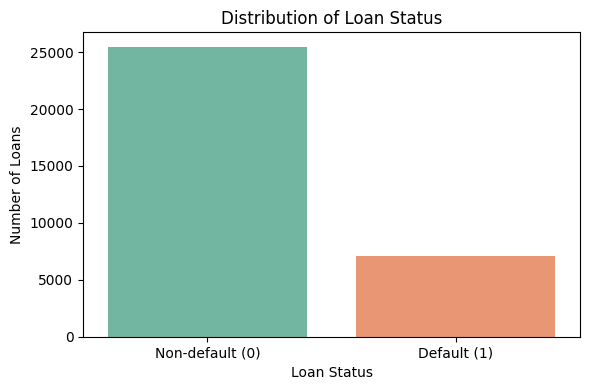

loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='loan_status', hue='loan_status', palette='Set2', legend=False)
plt.xticks([0, 1], ['Non-default (0)', 'Default (1)'])
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')
plt.tight_layout()
plt.show()

print((df_clean['loan_status'].value_counts(normalize=True) * 100).round(2))

**Observation:** Non-default loans outnumber default loans by roughly 3.6 to 1.

### 3.2 Default Rate by Loan Grade
 The mean of `loan_status` within each grade is the proportion of loans that defaulted, which lets us compare groups of different sizes.

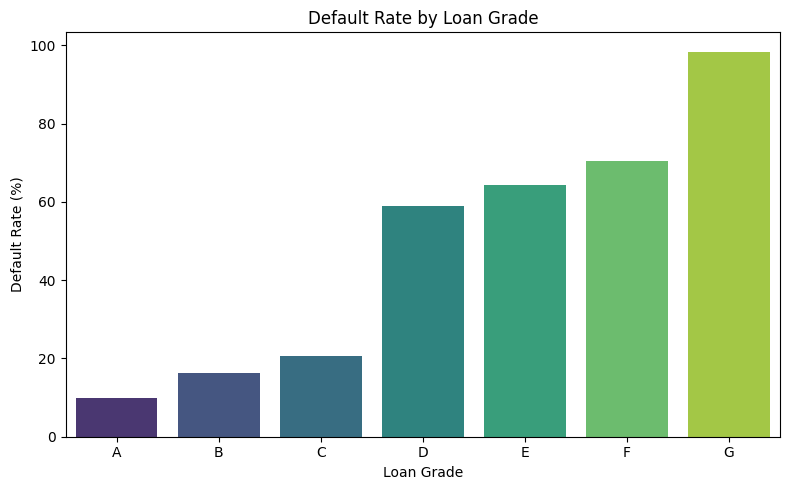

loan_grade
A     9.96
B    16.28
C    20.74
D    59.05
E    64.42
F    70.54
G    98.44
Name: loan_status, dtype: float64


In [68]:
default_rate_by_grade = df_clean.groupby('loan_grade')['loan_status'].mean() * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=default_rate_by_grade.index, y=default_rate_by_grade.values,
            hue=default_rate_by_grade.index, palette='viridis', legend=False)
plt.title('Default Rate by Loan Grade')
plt.xlabel('Loan Grade')
plt.ylabel('Default Rate (%)')
plt.tight_layout()
plt.show()

print(default_rate_by_grade.round(2))

**Observation:** The default rate rises steadily from about 10% for grade A to roughly 64-71% for grades E and F, and is almost 98% for grade G (a very small group). Loan grade is clearly associated with recorded default status.

### 3.3 Interest Rate and Loan-to-Income Ratio by Loan Status

Box plots compare the spread of a numerical variable across the two classes.

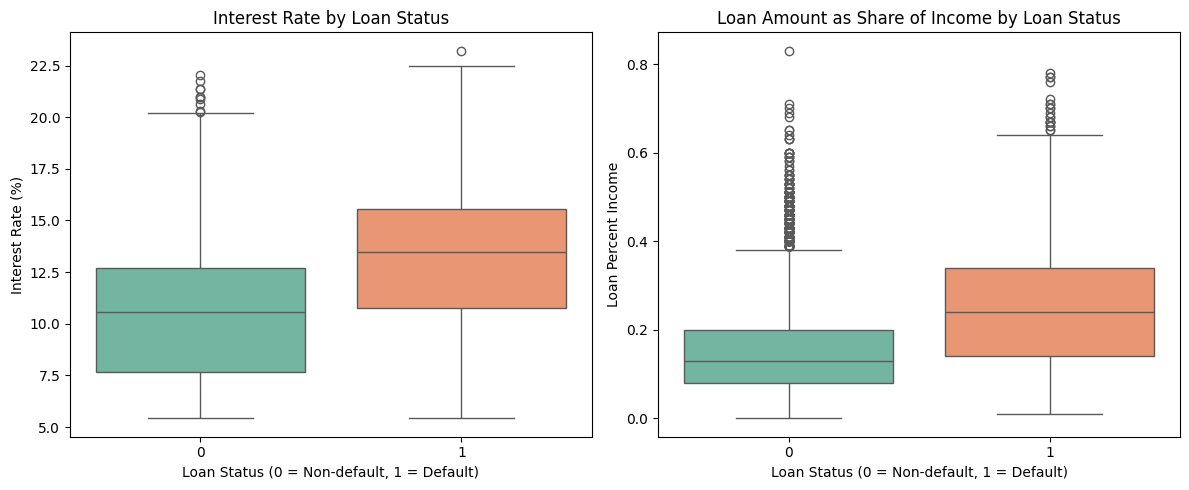

             loan_int_rate  loan_percent_income
loan_status                                    
0                    10.59                 0.13
1                    13.49                 0.24


In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_clean, x='loan_status', y='loan_int_rate', hue='loan_status', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Interest Rate by Loan Status')
axes[0].set_xlabel('Loan Status (0 = Non-default, 1 = Default)')
axes[0].set_ylabel('Interest Rate (%)')

sns.boxplot(data=df_clean, x='loan_status', y='loan_percent_income', hue='loan_status', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Loan Amount as Share of Income by Loan Status')
axes[1].set_xlabel('Loan Status (0 = Non-default, 1 = Default)')
axes[1].set_ylabel('Loan Percent Income')

plt.tight_layout()
plt.show()

print(df_clean.groupby('loan_status')[['loan_int_rate', 'loan_percent_income']].median().round(3))



**Observation:** Defaulted loans have higher median interest rates (13.49% vs 10.59%) and take a larger share of income (0.24 vs 0.13) than non-default loans. This is an association, not proof that these values cause default.

### 3.4 Correlation Heatmap

Correlation measures the strength of a *linear* relationship between two numerical variables (-1 to +1). It does not show causation.

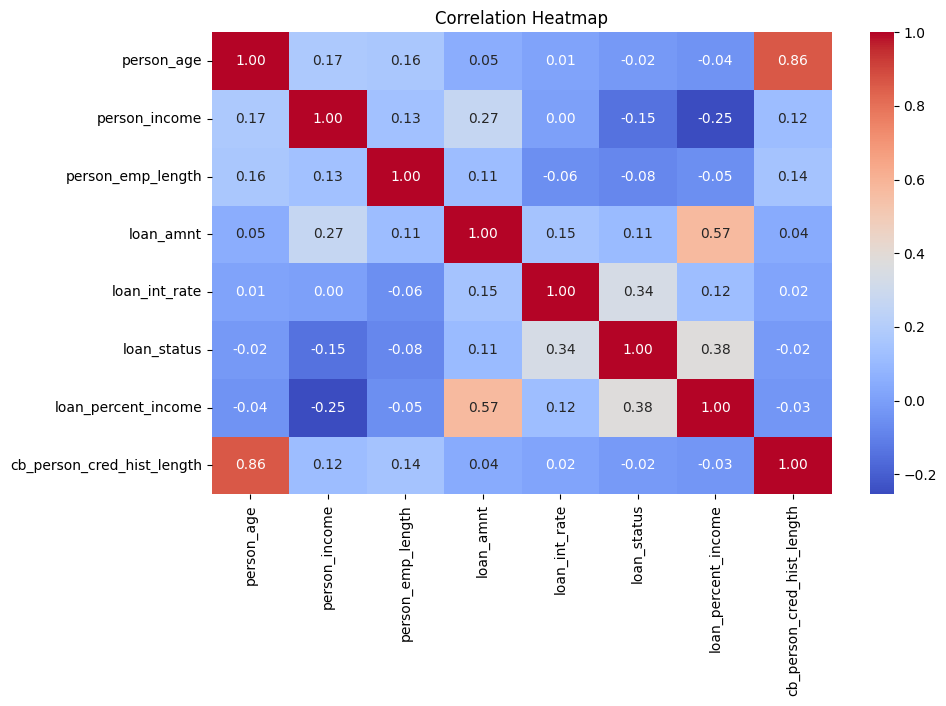

In [70]:
# Correlation Heatmap

numerical_data = df_clean.select_dtypes(include='number')
correlation = numerical_data.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

**Observation:** `loan_percent_income` (0.38) and `loan_int_rate` (0.34) have the strongest positive correlations with `loan_status`, while `person_income` is negatively correlated (-0.17). `person_age` and `cb_person_cred_hist_length` are strongly correlated with each other (0.88), meaning they carry overlapping information. All relationships with the target are only moderate.

# 4. Feature Engineering and Feature Preparation

We convert the categorical columns to numbers, separate the features from the target, split the data, fill missing values and scale the features.

### 4.1 Encoding Categorical Variables

Models need numeric input.
- `loan_grade` has a natural order (A is the best grade), so it gets **ordinal** codes 1 to 7.
- `cb_person_default_on_file` is binary (Y/N), so it becomes 1/0.
- `person_home_ownership` and `loan_intent` have no order, so they are **one-hot encoded** into 0/1 columns.

No new derived features are created: `loan_percent_income` already captures the loan-to-income ratio.

In [71]:
# Copy the cleaned dataset
df_model = df_clean.copy()

# Convert categorical values into numbers
df_model['loan_grade'] = df_model['loan_grade'].map({
    'A': 1, 'B': 2, 'C': 3, 'D': 4,
    'E': 5, 'F': 6, 'G': 7
})

df_model['cb_person_default_on_file'] = df_model[
    'cb_person_default_on_file'
].map({'N': 0, 'Y': 1})

# Convert remaining categorical columns into numerical columns
df_model = pd.get_dummies(
    df_model,
    columns=['person_home_ownership', 'loan_intent'],
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", df_model.shape)
display(df_model.head())

Shape after encoding: (32576, 18)


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22,59000,NaN,4,35000,16.02,1,0.59,1,3,0,0,1,0,0,0,1,0
1,21,9600,5.0,2,1000,11.14,0,0.10,0,2,0,1,0,1,0,0,0,0
2,25,9600,1.0,3,5500,12.87,1,0.57,0,3,0,0,0,0,0,1,0,0
3,23,65500,4.0,3,35000,15.23,1,0.53,0,2,0,0,1,0,0,1,0,0
4,24,54400,8.0,3,35000,14.27,1,0.55,1,4,0,0,1,0,0,1,0,0


### 4.2 Separating Features and Target

In [72]:
X = df_model.drop(columns='loan_status')
y = df_model['loan_status']

class_labels = ['Non-default', 'Default']

print("Features:", X.shape)
print("Target:", y.shape)


Features: (32576, 17)
Target: (32576,)


### 4.3 Train-Test Split

The model learns from the training set and is judged on the unseen test set. `stratify=y` keeps the default proportion the same in both sets, and `random_state=42` makes the split reproducible.

In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nDefault proportion in training set:", round(y_train.mean(), 4))
print("Default proportion in testing set:", round(y_test.mean(), 4))

Training set: (26060, 17)
Testing set: (6516, 17)

Default proportion in training set: 0.2182
Default proportion in testing set: 0.2182


### 4.4 Filling Missing Values Using Training Data Only

The median is calculated from the **training set** and applied to both sets, so no information from the test set leaks into preprocessing.

In [74]:
# Fill missing values using training-set medians
columns = ['person_emp_length', 'loan_int_rate']
medians = X_train[columns].median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing values in training set:", X_train.isnull().sum().sum())
print("Missing values in testing set:", X_test.isnull().sum().sum())

Missing values in training set: 0
Missing values in testing set: 0


### 4.5 Feature Scaling

KNN measures distances and Logistic Regression is sensitive to feature size, so a large-valued column such as income could dominate small ones. `StandardScaler` rescales each feature to mean 0 and standard deviation 1. It is **fitted on the training set only**, then used to transform the test set.

Decision Tree and Random Forest split on thresholds, so they do not need scaling. Gaussian Naive Bayes also works on the unscaled data here.

In [75]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training mean:", X_train_scaled.mean().round(3))
print("Scaled training std:", X_train_scaled.std().round(3))

Scaled training mean: 0.0
Scaled training std: 1.0


# 5. Classification Models

Five classifiers are trained on the training set and evaluated on the test set. **Default (1)** is the positive class.

### 5.1 Setting Up Evaluation

The helper function calculates the four metrics from a model's test predictions and stores them, so the comparison in Section 7 uses computed values only.

In [76]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []        # stores the metrics of each model
predictions = {}    # stores the test predictions of each model

def evaluate_model(name, y_pred):
    predictions[name] = y_pred
    scores = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    }
    results.append(scores)
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1-score']:
        print(f"{name} {metric}: {scores[metric]:.4f}")

### 5.2 Logistic Regression

Estimates the probability of default as a linear combination of the scaled features.

In [77]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
evaluate_model('Logistic Regression', lr_pred)

Logistic Regression Accuracy: 0.8547
Logistic Regression Precision: 0.7373
Logistic Regression Recall: 0.5190
Logistic Regression F1-score: 0.6092


**Interpretation:** Accuracy is 85.5%, but recall is only about 52%, so nearly half of the real defaults are missed.

### 5.3 K-Nearest Neighbors (KNN)

Classifies a loan by the majority class among its `k = 5` nearest training loans. Distances need scaled data.

In [78]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)
evaluate_model('KNN', knn_pred)

KNN Accuracy: 0.8910
KNN Precision: 0.8640
KNN Recall: 0.5942
KNN F1-score: 0.7042


**Interpretation:** KNN improves on Logistic Regression in every metric (F1-score about 0.70), suggesting that similar loans tend to share the same outcome.

### 5.4 Gaussian Naive Bayes

Applies Bayes' theorem and assumes the features are independent and roughly normally distributed within each class. It is simple and fast, but these assumptions are only approximate here.

In [79]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)
evaluate_model('Gaussian Naive Bayes', nb_pred)

Gaussian Naive Bayes Accuracy: 0.8197
Gaussian Naive Bayes Precision: 0.6631
Gaussian Naive Bayes Recall: 0.3530
Gaussian Naive Bayes F1-score: 0.4608


**Interpretation:** This is the weakest model so far: recall is about 36%, so it misses most defaults. The independence and normality assumptions do not fit this data well.

### 5.5 Decision Tree

Learns a sequence of yes/no questions on feature values. `max_depth=5` keeps the tree readable and limits overfitting.

In [80]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
evaluate_model('Decision Tree', dt_pred)

Decision Tree Accuracy: 0.9091
Decision Tree Precision: 0.9570
Decision Tree Recall: 0.6111
Decision Tree F1-score: 0.7459


**Interpretation:** The tree reaches 91% accuracy with very high precision (about 96%) but recall of about 62%: when it predicts default it is usually right, yet it misses many real defaults.

### 5.6 Decision Tree Visualization

Only the top three levels are drawn so the diagram stays readable. Each box shows the splitting rule, the class counts and the majority class.

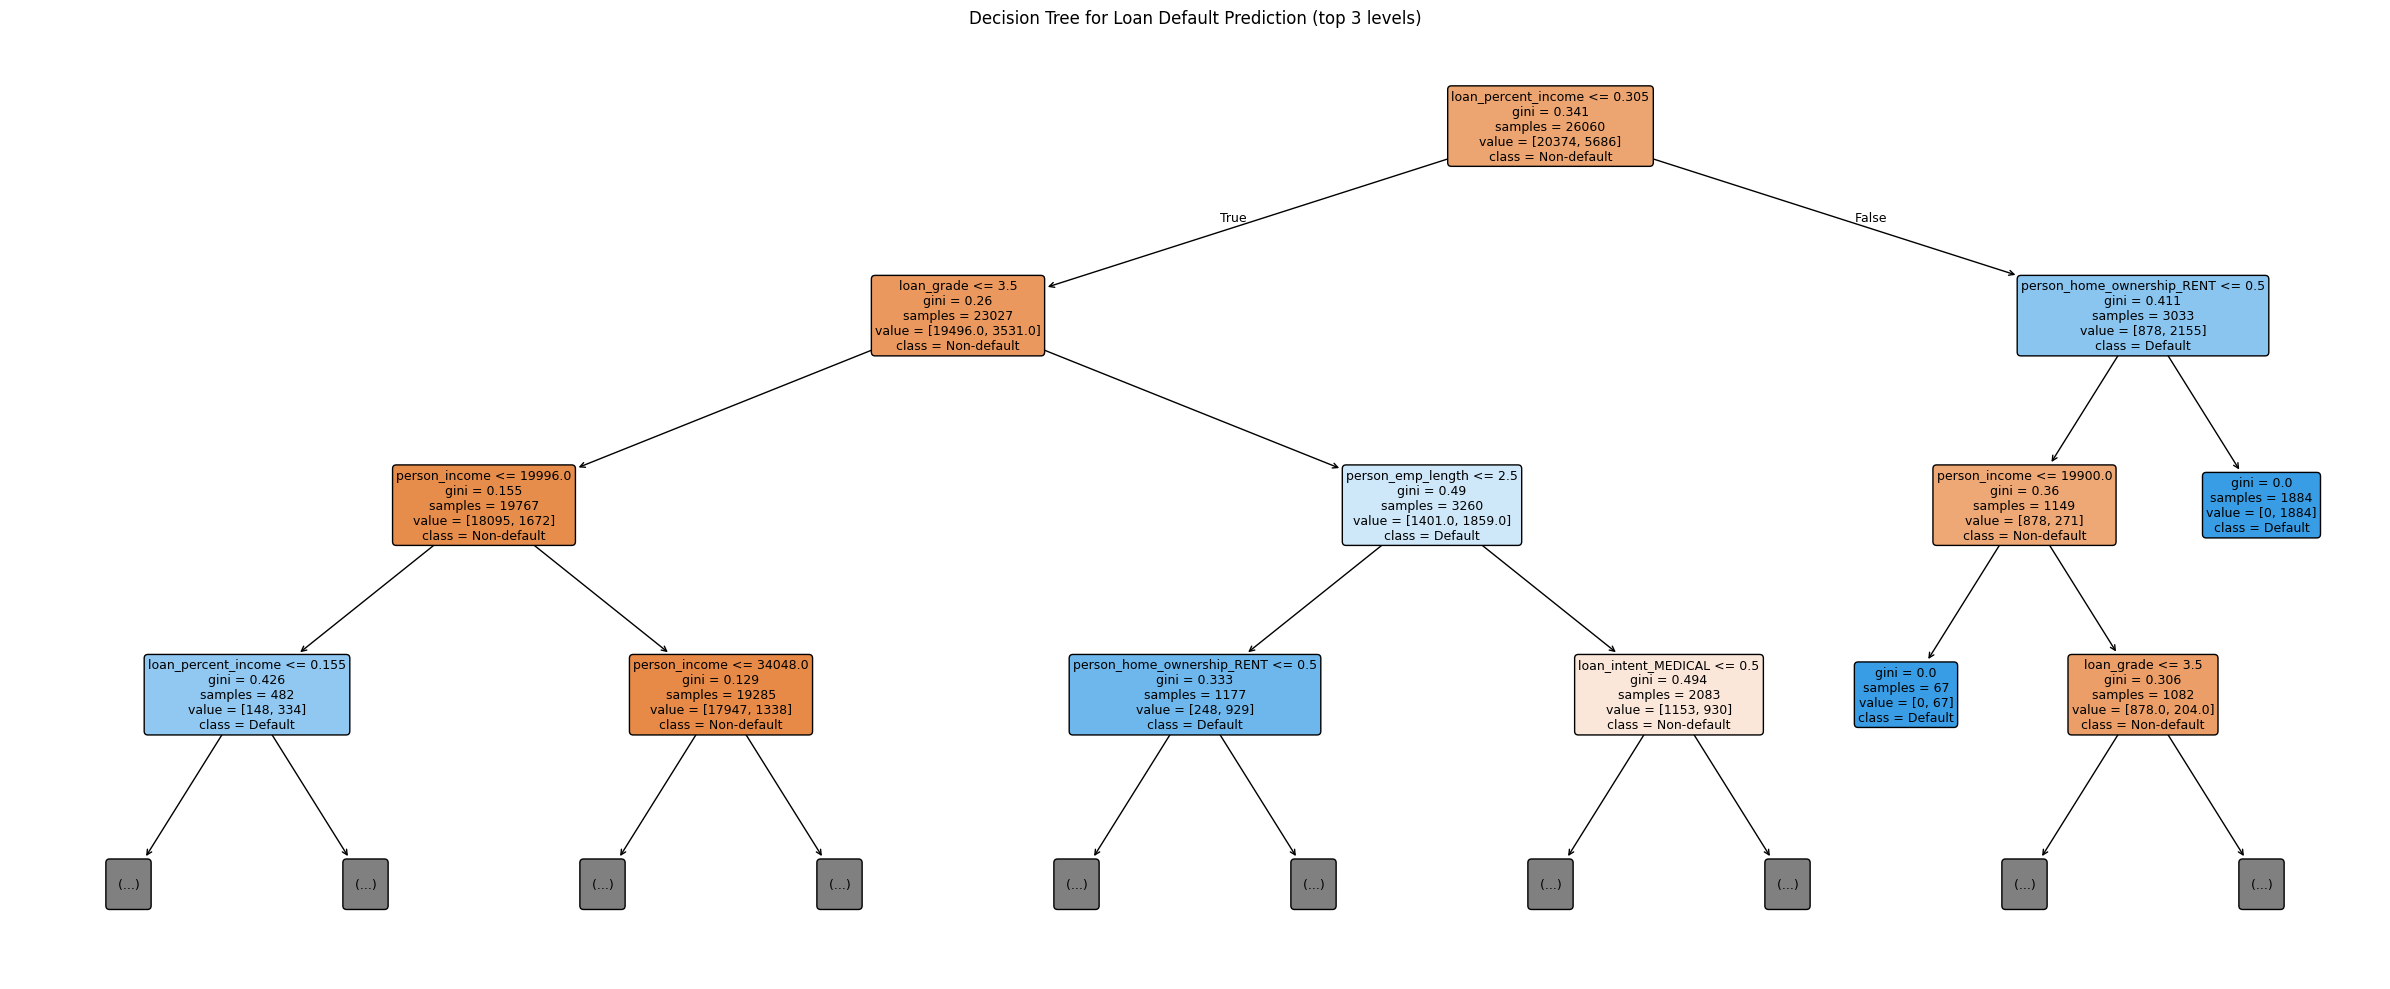

In [81]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 10))
plot_tree(
    dt_model,
    feature_names=X_train.columns.tolist(),
    class_names=class_labels,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree for Loan Default Prediction (top 3 levels)')
plt.tight_layout()
plt.show()

**Interpretation:** The first split is on `loan_percent_income` (at 0.31), followed by splits on `loan_grade`, `person_home_ownership_RENT`, `person_income` and `person_emp_length`. These are the features the tree found most useful for separating the classes, which agrees with the EDA.

### 5.7 Random Forest

Builds 100 decision trees on random samples of the data and combines their votes, which is usually more stable than a single tree.

In [82]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
evaluate_model('Random Forest', rf_pred)

Random Forest Accuracy: 0.9332
Random Forest Precision: 0.9660
Random Forest Recall: 0.7194
Random Forest F1-score: 0.8247


**Interpretation:** Random Forest gives the highest accuracy (93.4%), precision (96.8%) and recall (72.2%) so far, showing the benefit of combining many trees.

# 6. Model Evaluation

All five models are judged on the same test set using accuracy, precision, recall, F1-score, confusion matrices and classification reports.

| Metric | Meaning |
|---|---|
| **Accuracy** | Proportion of all predictions that are correct. |
| **Precision** | Of the loans predicted as default, the proportion that really defaulted. |
| **Recall** | Of the loans that really defaulted, the proportion the model found. |
| **F1-score** | Harmonic mean of precision and recall (a balance of the two). |
| **Confusion matrix** | Counts of correct and incorrect predictions for each class. |

### 6.1 Why Accuracy Alone Is Not Enough

If most loans are non-default, a model that always predicts "non-default" would still look accurate. We compute that baseline for comparison.

In [83]:
baseline_accuracy = 1 - y_test.mean()
print("Accuracy of always predicting 'Non-default':", round(baseline_accuracy, 4))

Accuracy of always predicting 'Non-default': 0.7818


**Observation:** A model that predicts "non-default" for every loan would already score about 78% accuracy while finding **no** defaults. So an accuracy of 85% is only a small improvement, and recall and F1-score are needed to judge how well defaults are detected.

### 6.2 Confusion Matrices of All Five Models

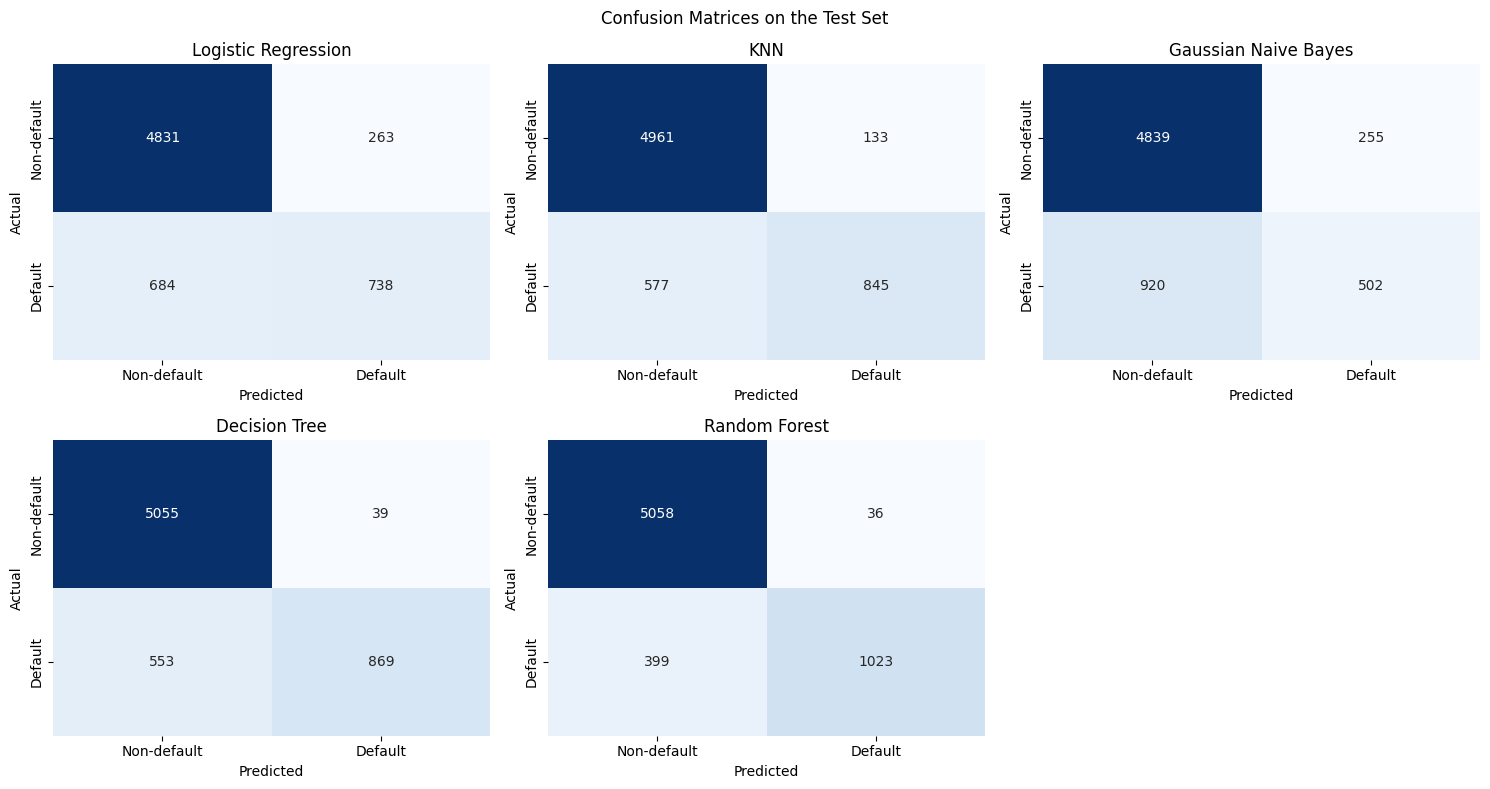

In [84]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

axes[-1].axis('off')
plt.suptitle('Confusion Matrices on the Test Set')
plt.tight_layout()
plt.show()

**Observation:** In every model the non-default class is identified well (top-left cell). The main weakness is the bottom-left cell: real defaults predicted as non-default (false negatives). For every model, false negatives are more numerous than false positives, which is why recall is lower than precision.

### 6.3 Classification Reports

In [85]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print("=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(y_test, y_pred, target_names=class_labels, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

 Non-default       0.88      0.95      0.91      5094
     Default       0.74      0.52      0.61      1422

    accuracy                           0.85      6516
   macro avg       0.81      0.73      0.76      6516
weighted avg       0.85      0.85      0.84      6516

KNN
              precision    recall  f1-score   support

 Non-default       0.90      0.97      0.93      5094
     Default       0.86      0.59      0.70      1422

    accuracy                           0.89      6516
   macro avg       0.88      0.78      0.82      6516
weighted avg       0.89      0.89      0.88      6516

Gaussian Naive Bayes
              precision    recall  f1-score   support

 Non-default       0.84      0.95      0.89      5094
     Default       0.66      0.35      0.46      1422

    accuracy                           0.82      6516
   macro avg       0.75      0.65      0.68      6516
weighted avg       0.80      

**Observation:** All models score higher on the non-default class than on the default class. The default class is smaller and harder to detect, so its precision, recall and F1-score are the most informative figures for comparing the models.

# 7. Model Comparison and Visualization

### 7.1 Comparison Table

The table is built from the computed results. **F1-score** is the primary selection criterion because it balances precision (avoiding false alarms) and recall (finding real defaults), and it is not inflated by the large non-default class the way accuracy can be.

In [86]:
comparison_df = pd.DataFrame(results).sort_values(by='F1-score', ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9332,0.9660,0.7194,0.8247
1,Decision Tree,0.9091,0.9570,0.6111,0.7459
2,KNN,0.8910,0.8640,0.5942,0.7042
3,Logistic Regression,0.8547,0.7373,0.5190,0.6092
4,Gaussian Naive Bayes,0.8197,0.6631,0.3530,0.4608


### 7.2 F1-score Comparison Chart

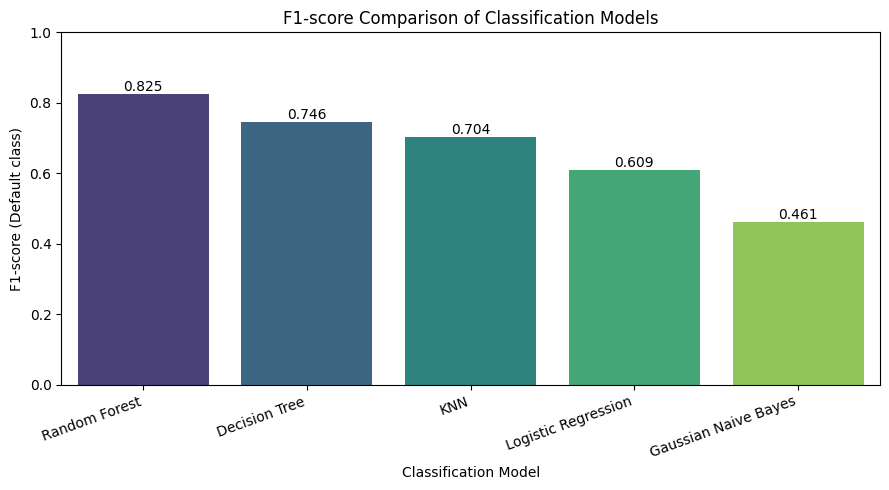

In [87]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=comparison_df, x='Model', y='F1-score', hue='Model', palette='viridis', legend=False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')

plt.title('F1-score Comparison of Classification Models')
plt.xlabel('Classification Model')
plt.ylabel('F1-score (Default class)')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 7.3 Selecting the Best Model

In [88]:
best_model_name = comparison_df.loc[comparison_df['F1-score'].idxmax(), 'Model']
best_row = comparison_df[comparison_df['Model'] == best_model_name].iloc[0]

print("Best model by F1-score:", best_model_name)
print("Accuracy :", round(best_row['Accuracy'], 4))
print("Precision:", round(best_row['Precision'], 4))
print("Recall   :", round(best_row['Recall'], 4))
print("F1-score :", round(best_row['F1-score'], 4))

Best model by F1-score: Random Forest
Accuracy : 0.9332
Precision: 0.966
Recall   : 0.7194
F1-score : 0.8247


**Interpretation:** Random Forest has the highest F1-score (0.827), and it also leads in accuracy, precision and recall, so the choice does not depend on which metric is used. The ranking by F1-score is Random Forest, Decision Tree, KNN, Logistic Regression and Gaussian Naive Bayes. The two tree-based models clearly outperform the other three on this dataset.

# 8. Best Model Analysis

The confusion matrix and classification report below use the **test predictions of the selected model**.

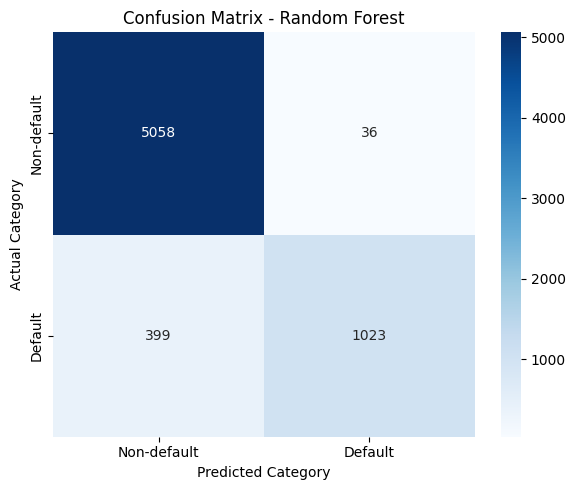

True Negatives (non-default predicted correctly): 5058
False Positives (non-default flagged as default): 36
False Negatives (defaults missed): 399
True Positives (defaults found): 1023

Classification Report - Random Forest
              precision    recall  f1-score   support

 Non-default       0.93      0.99      0.96      5094
     Default       0.97      0.72      0.82      1422

    accuracy                           0.93      6516
   macro avg       0.95      0.86      0.89      6516
weighted avg       0.94      0.93      0.93      6516



In [89]:
best_pred = predictions[best_model_name]
cm_best = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix - ' + best_model_name)
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_best.ravel()
print("True Negatives (non-default predicted correctly):", tn)
print("False Positives (non-default flagged as default):", fp)
print("False Negatives (defaults missed):", fn)
print("True Positives (defaults found):", tp)

print("\nClassification Report - " + best_model_name)
print(classification_report(y_test, best_pred, target_names=class_labels))

**Interpretation of the confusion matrix (test set, 6,483 loans):**
- 5,031 non-default loans were correctly predicted and only 34 were wrongly flagged as default (very few false alarms).
- 1,024 defaults were correctly found, but 394 defaults were missed (labelled non-default).

**Precision = 0.97:** when the model predicts default, it is correct about 97% of the time.
**Recall = 0.72:** it finds about 72% of the loans that actually defaulted.
**F1-score = 0.83:** a balance between the two.

**Trade-off:** This model rarely raises a false alarm but misses roughly 28% of defaults. A lender who cares more about catching defaults would prefer higher recall, even at the cost of more false alarms (rejecting some good borrowers). The results come from one dataset and one train-test split, so they should not be treated as reliable enough for real lending decisions without independent validation.

# 9. Key Findings and Conclusion

## Key Findings

**Data preparation:** 165 duplicate rows and 5 records with impossible ages were removed. Two impossible employment-length values were treated as missing. Missing values were filled using training-set medians after the split. Categorical variables were encoded (ordinal for `loan_grade`, one-hot for the others), the data was split 80/20 with stratification, and `StandardScaler` was fitted on the training data only.

**EDA observations:** About 22% of loans are recorded as defaults. Default rates rise sharply with worse loan grades, and defaulted loans have higher interest rates and a larger share of income. These are associations, not causes.

**Model comparison (test set):**

| Model | F1-score |
|---|---|
| Random Forest | 0.827 |
| Decision Tree | 0.752 |
| KNN | 0.697 |
| Logistic Regression | 0.609 |
| Gaussian Naive Bayes | 0.467 |

**Selected model:** **Random Forest**, chosen using the F1-score as the primary criterion (accuracy 93.4%, precision 96.8%, recall 72.2%). It identifies most defaults with very few false alarms, but still misses about 28% of defaults.

## Limitations

- Results depend on this dataset, the particular train-test split, the preprocessing choices and the selected models.
- The data is imbalanced, and loan grade and interest rate are set by the lender, so they may already reflect the lender's own risk assessment.
- Missing interest rates (about 10%) were filled with the median, which may hide useful information.
- Patterns found are associations, not causes, and the test set was used once, with no repeated validation.
- This is an educational prediction exercise, not a complete credit-decision system.

## Recommendations & Future Scope

**Recommendations (Based on Analysis):**
- **Stricter Checks for High-Risk Grades:** Applicants in Loan Grades D to G and those with a loan-to-income ratio above 25% show the highest default rates and should require additional verification or collateral.
- **Interest Rate Caps for Renters:** Since borrowers living in rented housing with high interest rates (>13%) default more frequently, lenders can offer structured repayment plans or lower loan limits for this group.

**Future Scope:**
- **Cross-Validation & Hyperparameter Tuning:** Apply k-fold cross-validation for more stable results and tune model settings (such as tree depth and number of trees) to improve recall on default cases.
- **Handling Class Imbalance:** Use resampling techniques like SMOTE or class weights to handle the 78:22 class imbalance more directly.
- **Feature Importance & Deployment:** Examine which features matter most to the Random Forest/Decision Tree models and deploy the final model as a simple web application for real-time loan screening.